In [97]:
import xarray as xr
import pandas as pd
import numpy as np


In [98]:
filename = '/home/cr2/cmtorres/ARs_DATA/Global_AR_dataset_Guan.nc'
ds = xr.open_dataset(filename).sel(time=slice('2018-11-01', '2022-03-31'), ens = 1, lev = 0)['shapemap']
ds.coords['lon'] = (ds.coords['lon'] + 180) % 360 - 180
ds = ds.sortby(ds.lon)
ds = ds.sel(lon=slice(-150, -30), lat=slice(-35, -75))
#ds = ds.sel(time=ds['time'].dt.month.isin([11, 12, 1, 2, 3]))

ds_AP = ds.sel(lon=slice(-73, -55), lat=slice(-61, -69))


In [99]:
df_AR_6h = ds_AP.sum(dim=['lat', 'lon']).to_dataframe()

In [100]:
df_AR_6h

AR_active = ds.sel(time=df_AR_6h[df_AR_6h["shapemap"] > 1].index)

In [101]:
ar_times = pd.to_datetime(AR_active.time.values)
time_diffs = ar_times.to_series().diff()
split_indices = np.where(time_diffs > pd.Timedelta(hours=12))[0]
ar_events = np.split(ar_times, split_indices)


In [102]:
import numpy as np
import pandas as pd


def get_ar_event_durations(ar_active_time, threshold_hours=12):
    """Splits active AR times into events and extracts start time, end time,

    and duration in hours for each event.
    """
    if len(ar_active_time) == 0:
        return pd.DataFrame(columns=["start", "end", "duration_hours"])

    ar_times = pd.to_datetime(ar_active_time)
    time_diffs = ar_times.to_series().diff()

    # Find split indices based on the threshold
    split_indices = np.where(time_diffs > pd.Timedelta(hours=threshold_hours))[
        0
    ]
    ar_events = np.split(ar_times, split_indices)

    # Extract start, end, and duration (in hours) for each continuous event
    event_data = []
    for event in ar_events:
        start = event[0]
        end = event[-1]
        # Duration calculation: includes span between start and end timestamps
        duration_hours = (end - start).total_seconds() / 3600.0

        event_data.append(
            {"start": start, "end": end, "duration_hours": duration_hours}
        )

    return pd.DataFrame(event_data)

In [103]:
# Assuming AR_active.time exists:
df_events = get_ar_event_durations(AR_active.time.values)
df_events

,start,end,duration_hours
0,2018-11-01 00:00:00,2018-11-01 12:00:00,12.0
1,2018-11-03 00:00:00,2018-11-06 06:00:00,78.0
2,2018-11-10 06:00:00,2018-11-12 12:00:00,54.0
3,2018-11-13 18:00:00,2018-11-13 18:00:00,0.0
4,2018-11-15 18:00:00,2018-11-18 18:00:00,72.0
...,...,...,...
282,2022-03-18 12:00:00,2022-03-23 00:00:00,108.0
283,2022-03-24 00:00:00,2022-03-24 06:00:00,6.0
284,2022-03-25 06:00:00,2022-03-27 18:00:00,60.0
285,2022-03-28 12:00:00,2022-03-30 00:00:00,36.0


In [104]:
ds_sel = ds.sel(time=slice(df_events.start[2], df_events.end[2]),)

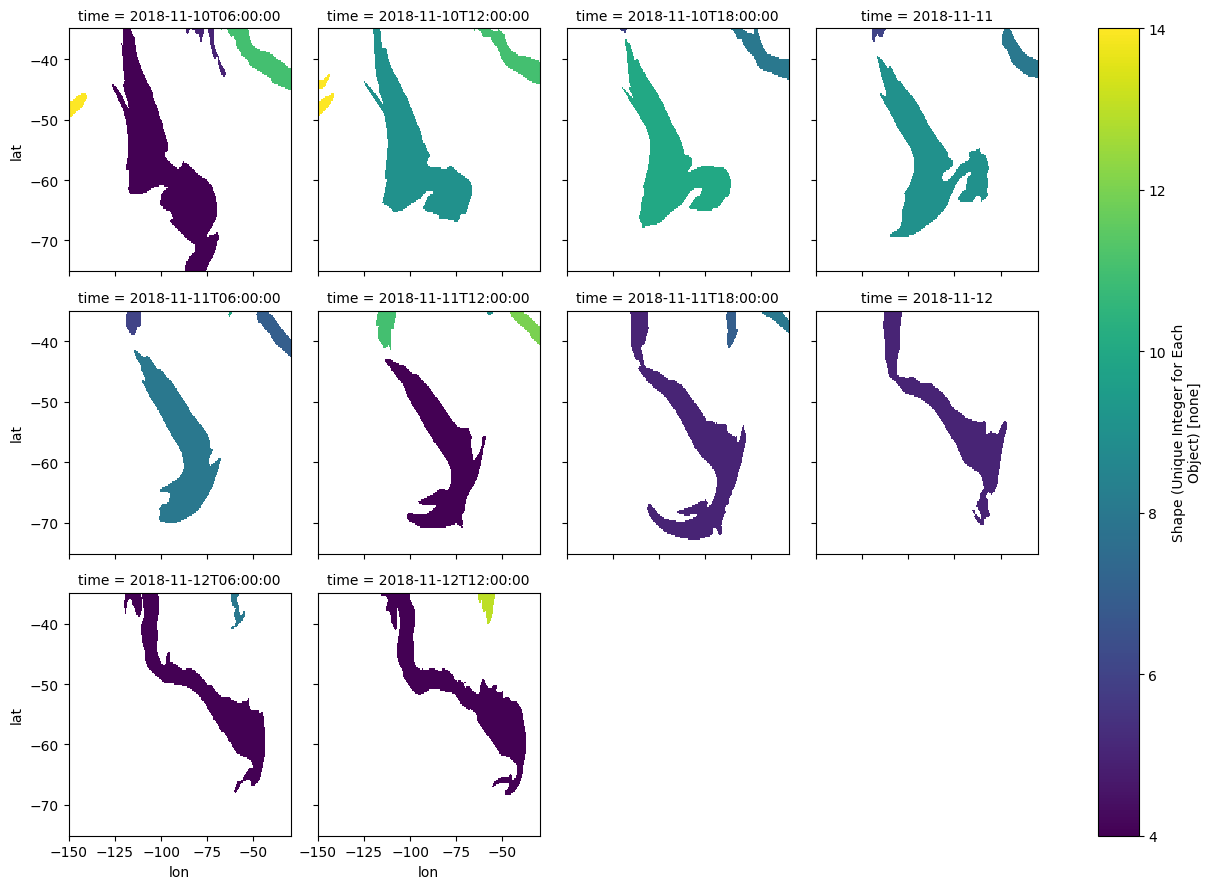

In [105]:
ds_sel.plot(x='lon', y='lat', col="time", col_wrap=4)